<a href="https://colab.research.google.com/github/ab110404/MAT422/blob/main/HW3.5%2C3.6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW 3.5 and 3.6

3.5. K-means
- In this example, I will use Python to divide a dataset intro three clusters and visualize the results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, _ = make_blobs(
    n_samples=150,
    centers=3,
    cluster_std=0.8,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Number of observations:", len(X))

Dataset shape: (150, 2)
Number of observations: 150


- Before applying K-means, I will create a scatter plot of the observations.
- The data contains 150 observations with two numerical features.
- The graph will help me identify whether the observations appear to form separate groups.

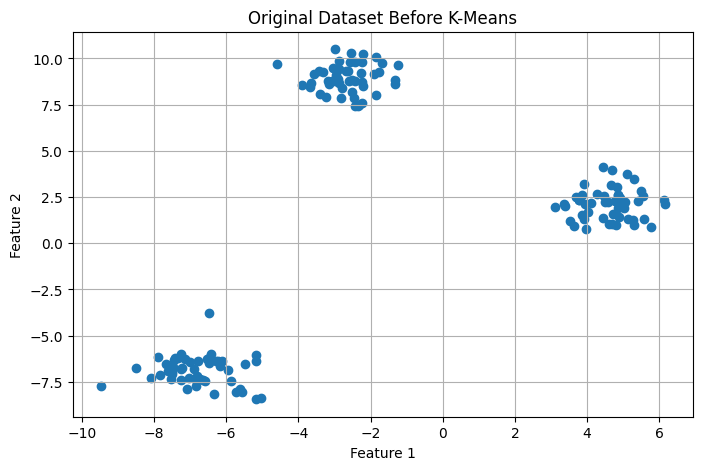

In [2]:
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Dataset Before K-Means")
plt.grid(True)
plt.show()

- I will use K-means clustering with k=3.
- The algorithm will divide the observations into three clusters based on their distances from the centroids. Each observation will be assigned a cluster label, and the centroid of each cluster will be calculated.

In [3]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

print("Number of clusters:", kmeans.n_clusters)
print("Centroids:")
print(np.round(centroids, 2))

Number of clusters: 3
Centroids:
[[-2.66  8.93]
 [-6.78 -6.89]
 [ 4.6   2.11]]


- Now I will graph the observation using different colors to represent their assigned clusters.
- I will also mark the centroids to show the center of each cluster.
- This visualization will help demonstrate how k-means separates observations into groups.

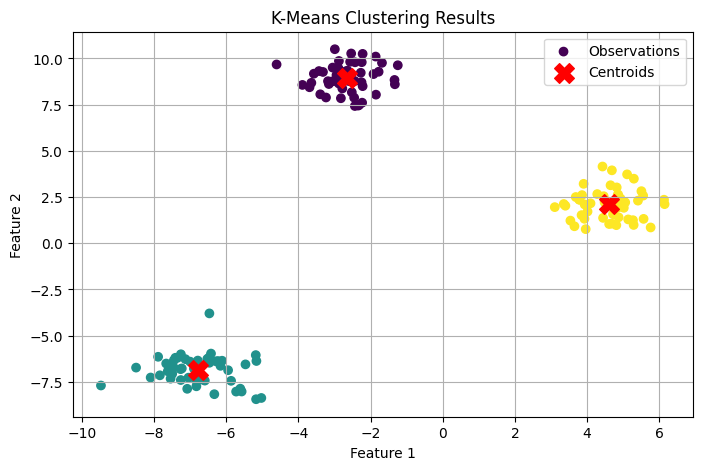

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis",
    label="Observations"
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering Results")
plt.legend()
plt.grid(True)
plt.show()

- K-means attempts to minimize the sum of squared distances between observations and their assigned centroids.
- This measurement is called the within-cluster sum of squares (WCSS)
- I will now calculate the WCSS for the three-cluster model.

In [5]:
wcss = kmeans.inertia_
print("Within-cluster sum of squares:", round(wcss, 4))

Within-cluster sum of squares: 181.5044


- I will calculate WCSS for different values of k, ranging from 1 to 8.
- I will also graph the results to identify where the improvement in WCSS begins to slow down.

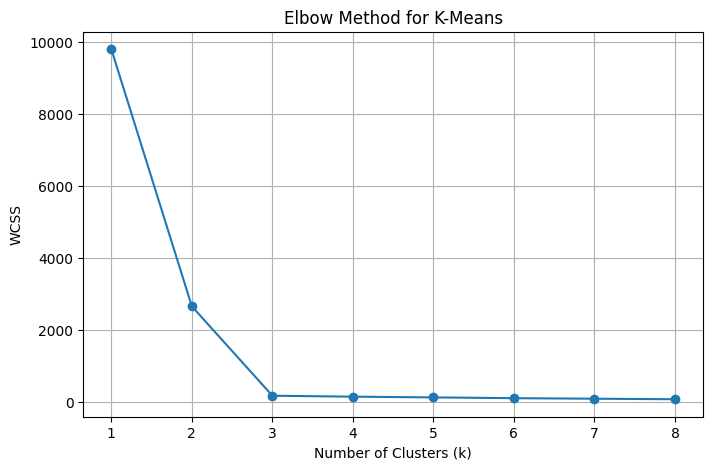

In [6]:
wcss_values = []

for k in range(1, 9):
  model = KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10

  )

  model.fit(X)
  wcss_values.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 9),
    wcss_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method for K-Means")
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()

Conclusion:
- In this sectin, I explored K-means clustering as an unsupervised machine learning method.
- This example demonstrates how K-means can organize observations into groups based on their similarities.

3.6. Support vector machine
- In this example, I will use Python to classify two groups of observations using a linear SVM.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(
    n_samples=100,
    centers=[[-2, -2], [2, 2]],
    cluster_std=0.8,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Number of observations:", len(y))
print("Classes:", np.unique(y))

Dataset shape: (100, 2)
Number of observations: 100
Classes: [0 1]


- Before applying SVM, I will graph the observations.
- The dataset contains 100 observations with two features. Each observation belongs to one of two classes, represented by 0 and 1.
- The scatter plot will help visualize how the two classes are separated.

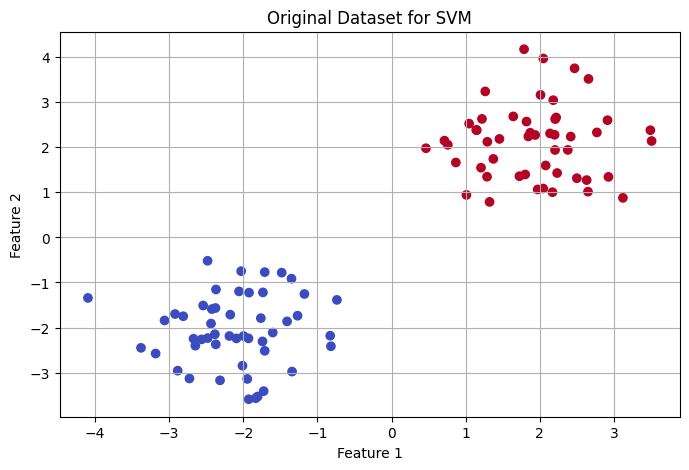

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Dataset for SVM")
plt.grid(True)
plt.show()

- I will use a linear support vector machine to classify the observations.
- The linear kernel creates a straight decision boundary between the two classes.
- The model will determine the best boundary by balancing a large margin with classification errors. I will use C=1.0, as the regularization parameter.

In [11]:
svm_model = SVC(kernel="linear", C=1.0)
svm_model.fit(X, y)
print("Model trained successfully.")
print("Number of support vectors:", len(svm_model.support_vectors_))
print("Training accuracy:", round(svm_model.score(X, y), 4))

Model trained successfully.
Number of support vectors: 3
Training accuracy: 1.0


- I will now plot the margin boundaries and highlight the support vectors.
- This graph will demonstrate how SVM separates the observations into different categories.

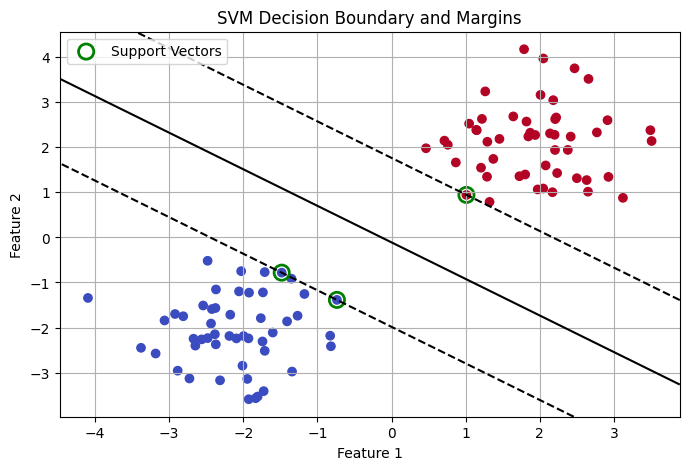

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm"
)

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 200)
yy = np.linspace(ylim[0], ylim[1], 200)

YY, XX = np.meshgrid(yy, xx)
xy = np.column_stack([XX.ravel(), YY.ravel()])
Z = svm_model.decision_function(xy).reshape(XX.shape)
plt.contour(
    XX, YY, Z,
    levels=[-1, 0, 1],
    colors="black",
    linestyles=["--", "-", "--"]
)

plt.scatter(
    svm_model.support_vectors_[:, 0],
    svm_model.support_vectors_[:, 1],
    s=120,
    facecolors="none",
    edgecolors="green",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("SVM Decision Boundary and Margins")
plt.legend()
plt.grid(True)
plt.show()

- After training the SVM model, I can use it to classify new observations.
- The model predicts the class based on which side of the decision boundary the point falls.
- I will test the model using four new observations.

In [13]:
new_points = np.array([
    [-3, -2],
    [-1, -1],
    [1, 1],
    [3, 2]
])

predictions = svm_model.predict(new_points)

for point, prediction in zip(new_points, predictions):
  print(f"Point {point} belongs to Class {prediction}")

Point [-3 -2] belongs to Class 0
Point [-1 -1] belongs to Class 0
Point [1 1] belongs to Class 1
Point [3 2] belongs to Class 1


- I will compare different values of C to examine how they affect the model.

In [14]:
C_values = [0.1, 1, 10, 100]
for c in C_values:
  model = SVC(kernel="linear", C=c)
  model.fit(X, y)
  print(
      f"C = {c} "
      f"Accuracy = {model.score(X, y):.4f}, "
      f"Support vectors = {len(model.support_vectors_)}"
  )

C = 0.1 Accuracy = 1.0000, Support vectors = 6
C = 1 Accuracy = 1.0000, Support vectors = 3
C = 10 Accuracy = 1.0000, Support vectors = 3
C = 100 Accuracy = 1.0000, Support vectors = 3


Conclusion:
- In this section, I explored Support Vector Machine as a supervised machine learning method.
- This example demonstrates how SVM uses a decision boundary and margin optimization to classify observations.